In [1]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator
from astropy.time import Time
from typing import Union, List

import frb_functions

from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as ticker

In [2]:
import matplotlib
# matplotlib.rcParams['mathtext.fontset'] = 'custom'
# matplotlib.rcParams['mathtext.fontset'] = 'stix'
# matplotlib.rcParams['font.family'] = 'STIXGeneral'

In [3]:
def rm_info(csv_file):
    """
    Load a CSV file into a pandas DataFrame using the first column as the index.

    Parameters:
        csv_file (str): Path to the CSV file.

    Returns:
        pandas.DataFrame: DataFrame with the first column set as the index.
    """
    df = pd.read_csv(csv_file, index_col=0)
    return df

In [4]:
def gaus(x,a,x0,sigma,d):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))+d

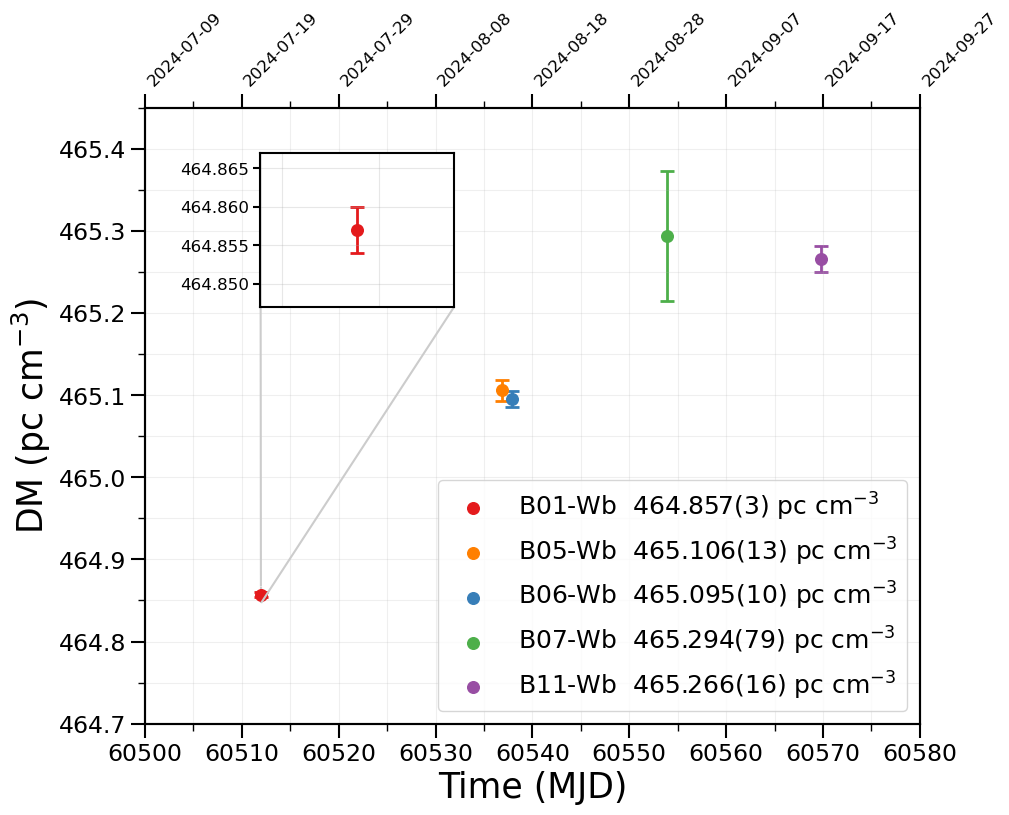

In [5]:
def dm_time(dm_list):
    
    # Figure
    fig, ax = plt.subplots(figsize=(10, 8))

    # Plot each burst with scatter and error bars
    for i, burst in enumerate(dm_list):
        plt.scatter(burst[3], burst[1], label=f"{burst[0]}", color=burst[4], s=70, zorder=2)
        plt.errorbar(
            x=burst[3], y=burst[1], 
            yerr=burst[2], fmt='o', 
            color=burst[4], ecolor=burst[4], 
            elinewidth=2, capsize=5, capthick=2, 
            alpha=1.0, linestyle='--', zorder=1
        )

    plt.ylabel(r'DM (pc cm$^{-3})$', size=25)
    plt.xlabel('Time (MJD)', size=25)
    plt.xlim(60500,60580)
    plt.ylim(464.7,465.45)

    # Customize ticks and axes for the main plot
    ax.tick_params(axis="x", bottom=True, top=True, labelbottom=True, labeltop=False)

    # Add a second x-axis on the top for human-readable dates
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())

    # Generate evenly spaced ticks based on the bottom axis
    mjd_ticks = ax.get_xticks()

    # Convert MJD values to human-readable dates
    human_readable_dates = Time(mjd_ticks, format='mjd').to_value('iso', subfmt='date')

    # Set the ticks for the top x-axis using the same MJD ticks
    ax_top.set_xticks(mjd_ticks)

    # Set human-readable date labels on the top axis
    ax_top.set_xticklabels(human_readable_dates, rotation=45, ha='left', fontsize=14)

    # Ensure the two x-axes are perfectly synchronized
    ax_top.set_xlim(ax.get_xlim())

    # Add inset for the first data point with custom coordinates
    #[x, y, width, height]
    inset_ax = inset_axes(ax, width="50%", height="50%", 
                          bbox_to_anchor=(-0.065, 0.472, 0.5, 0.5),  # Custom inset position
                          bbox_transform=ax.transAxes,  # Ensure coordinates are relative to the main plot
                          borderpad=2)

    # Plot the first data point in the inset
    burst = dm_list[0]  # Focusing on the first point
    inset_ax.scatter(burst[3], burst[1], color=burst[4], s=70, zorder=2)
    inset_ax.errorbar(
        x=burst[3], y=burst[1], 
        yerr=burst[2], fmt='o', 
        color=burst[4], ecolor=burst[4], 
        elinewidth=2, capsize=5, capthick=2, 
        alpha=1.0, linestyle='--', zorder=1
    )

    # Zoom in to make the small error visible in the inset
    inset_ax.set_xlim(burst[3] - 0.01, burst[3] + 0.01)
    inset_ax.set_ylim(burst[1] - 0.01, burst[1] + 0.01)

    # Disable scientific notation and force full decimal labels on the inset
    inset_ax.yaxis.set_major_formatter(ScalarFormatter(useOffset=False, useMathText=False))
    inset_ax.tick_params(axis="x", bottom=False, labelbottom=False)
    inset_ax.tick_params(axis='y', which='major', labelsize=15, width=1.5, length=5)
    for axis in ['top', 'bottom', 'left', 'right']:
        inset_ax.spines[axis].set_linewidth(1.5)
    
    # Aesthetic improvements for the inset
    inset_ax.tick_params(axis='both', which='major', labelsize=12)
    inset_ax.grid(True, alpha=0.3)  # Grid for inset axis

    # Add grid to the main axis
    ax.grid(which="both", alpha=0.2)  # Grid for main axis

    # Mark the inset area on the main plot
    mark_inset(ax, inset_ax, loc1=2, loc2=4, fc="none", ec="0.8", lw=1.5)

    # Aesthetic improvements for the main plot
    for axx in [ax_top, ax]:
        for axis in ['top', 'bottom', 'left', 'right']:
            axx.spines[axis].set_linewidth(1.5)
            axx.tick_params(axis='both', which='major', labelsize=17, width=1.5, length=10)
            axx.tick_params(axis='both', which='minor', labelsize=17, width=1, length=5)
            axx.xaxis.set_minor_locator(ticker.MultipleLocator(5.0))

    ax_top.set_xticklabels(human_readable_dates, rotation=45, ha='left', fontsize=12)
    ax.legend(loc="lower right", fontsize=18, fancybox=True)
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))

    # Display the plot
    plt.show()

    plot_name = f"dm_over_time_V3"
    # fig.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
    # fig.savefig(plot_name + ".png", facecolor='white', \
    #             transparent=False, format = 'png',bbox_inches='tight', dpi=300)
    plt.show()

dm_list = [
    ["B01-Wb  464.857(3)" + r" pc cm$^{-3}$", 464.857, 0.003, 60511.98778150463, "#e41a1c"],
    ["B05-Wb  465.106(13)"+ r" pc cm$^{-3}$", 465.106, 0.013, 60536.87820587847, "#ff7f00"],    
    ["B06-Wb  465.095(10)"+ r" pc cm$^{-3}$", 465.095, 0.010, 60537.88252653935, "#377eb8"],
    ["B07-Wb  465.294(79)"+ r" pc cm$^{-3}$", 465.294, 0.079, 60553.89310871119, "#4daf4a"],
    ["B11-Wb  465.266(16)"+ r" pc cm$^{-3}$", 465.266, 0.016, 60569.75872295139, "#984ea3"]
]

dm_time(dm_list)

In [6]:
def dm_rm_time_panel(dm_df, dm_color="#1b9e77", rm_colors=["#5e3c99", "#e66101"]):
    rm_df = pd.read_csv("../../nrt_polarization/RM_values_and_errors.csv")
    
    fig, (ax, ax2) = plt.subplots(ncols=2, figsize=(22, 8), sharey=False, gridspec_kw={"width_ratios": [1, 1], "wspace": 0.27})

    # --- Shared x-limits and ticks ---
    xlim = (60490, 60575)
    xticks_major = np.arange(60490, 60576, 20)

    # --- Left panel: DM vs. Time ---
    ax.errorbar(
        x=dm_df["MJD"], y=dm_df["DM"], yerr=dm_df["DM_err"], fmt='h', color=dm_color,
        ecolor=dm_color, elinewidth=3, capsize=10, capthick=3,
        alpha=1.0, zorder=1, label='Wb DM measurements', markersize=12
    )


    ax.set_ylabel(r'DM (pc cm$^{-3}$)', size=20)
    ax.set_xlabel('Time (MJD)', size=20)
    ax.set_xlim(xlim)
    ax.set_ylim(464.8, 465.4)
    ax.set_xticks(xticks_major)

    # Top axis for human-readable dates
    ax_top = ax.twiny()
    ax_top.set_xlim(xlim)
    ax_top.set_xticks(xticks_major)
    ax_top.set_xticklabels(Time(xticks_major, format='mjd').to_value('iso', subfmt='date'),
                           rotation=0, ha='center', fontsize=14)

    inset_ax = inset_axes(ax, width="50%", height="50%",
                          bbox_to_anchor=(-0.075, 0.378, 0.5, 0.5),
                          bbox_transform=ax.transAxes, borderpad=2)

    x0, y0, yerr0 = dm_df.iloc[0][["MJD", "DM", "DM_err"]]
    inset_ax.errorbar(x=x0, y=y0, yerr=yerr0, fmt='h', color=dm_color,
                      ecolor=dm_color, elinewidth=2, capsize=5, capthick=2,
                      alpha=1.0, zorder=1, markersize=12)
    
    inset_ax.scatter(x0, y0, color=dm_color, s=70, zorder=2)
    inset_ax.set_xlim(x0 - 0.01, x0 + 0.01)
    inset_ax.set_ylim(y0 - 0.01, y0 + 0.01)
    inset_ax.yaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    inset_ax.tick_params(axis="x", bottom=False, labelbottom=False)
    inset_ax.tick_params(axis='y', which='major', labelsize=15, width=1.5, length=5)
    for side in ['top', 'bottom', 'left', 'right']:
        inset_ax.spines[side].set_linewidth(1.5)
    inset_ax.tick_params(axis='both', which='major', labelsize=12)

    mark_inset(ax, inset_ax, loc1=3, loc2=4, fc="none", ec="0.8", lw=1.5)

    # Format both DM axes
    for axx in [ax, ax_top]:
        for side in ['top', 'bottom', 'left', 'right']:
            axx.spines[side].set_linewidth(1.5)
        axx.tick_params(axis='both', which='major', labelsize=17, width=1.5, length=10)
        axx.tick_params(axis='both', which='minor', labelsize=17, width=1, length=5)
        axx.xaxis.set_minor_locator(ticker.MultipleLocator(5.0))
        
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))


    # --- Right panel: RM vs. Time ---
    ax2.errorbar(
        x=rm_df['MJD'], y=rm_df['fit_RM_pcm60499'], yerr=rm_df['fit_RM_err_pcm60499'], color=rm_colors[0],
        marker='s', ls='', markersize=12, markeredgewidth=1, markeredgecolor='black', alpha=0.6, label='NRT Pol. calibration MJD 60499',\
        elinewidth=3, capsize=10, capthick=3,
    )
    ax2.errorbar(
        x=rm_df['MJD'], y=rm_df['fit_RM_pcm60598'], yerr=rm_df['fit_RM_err_pcm60598'], color=rm_colors[1],
        marker='s', ls='', markersize=12, markeredgewidth=1, markeredgecolor='black', alpha=0.6, label='NRT Pol. calibration MJD 60598',\
        elinewidth=3, capsize=10, capthick=3,
    )

    ax2.set_xlim(xlim)
    ax2.set_ylim(-100, -350)
    ax2.set_xticks(xticks_major)
    ax2.set_ylabel(r'RM (rad m$^{-2}$)', size=20)
    ax2.set_xlabel('Time (MJD)', size=20)

    # Top axis with ISO dates for RM
    ax2_top = ax2.twiny()
    ax2_top.set_xlim(xlim)
    ax2_top.set_xticks(xticks_major)
    ax2_top.set_xticklabels(Time(xticks_major, format='mjd').to_value('iso', subfmt='date'),
                            rotation=0, ha='center', fontsize=14)

    # Format both RM axes
    for axx in [ax2, ax2_top]:
        for side in ['top', 'bottom', 'left', 'right']:
            axx.spines[side].set_linewidth(1.5)
        axx.tick_params(axis='both', which='major', labelsize=17, width=1.5, length=10)
        axx.tick_params(axis='both', which='minor', labelsize=17, width=1, length=5)
        axx.xaxis.set_minor_locator(ticker.MultipleLocator(5.0))

    ax2.yaxis.set_minor_locator(ticker.MultipleLocator(25))
    
    for axx in [ax, inset_ax, ax2]:
        axx.grid(which="both", alpha=0.4)

    ax.legend(loc="lower right", fontsize=18, fancybox=True)
    ax2.legend(loc="lower right", fontsize=18, fancybox=True)

    fig.tight_layout()

    plot_name = f"dm_rm_over_time_V2"
    # fig.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
    # fig.savefig(plot_name + ".png", facecolor='white', \
    #             transparent=False, format = 'png',bbox_inches='tight', dpi=300)

    plt.show()

/tmp/ipykernel_1344107/1968495393.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


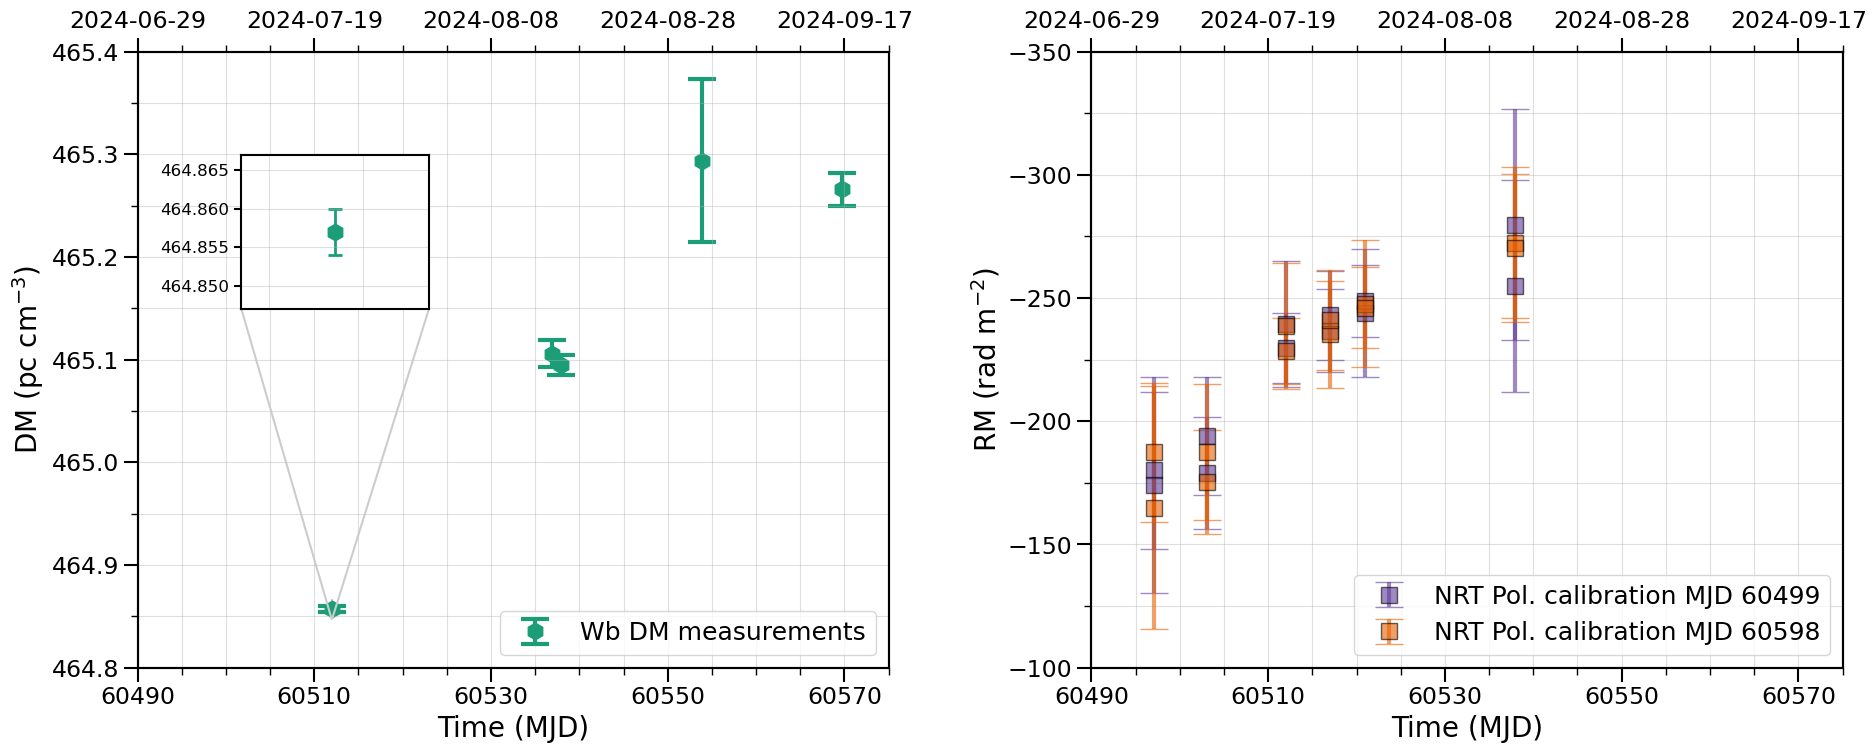

In [7]:
dm_df = pd.DataFrame({
    "MJD": [60511.987, 60536.878, 60537.882, 60553.893, 60569.758],
    "DM": [464.857, 465.106, 465.095, 465.294, 465.266],
    "DM_err": [0.003, 0.013, 0.010, 0.079, 0.016]
})

dm_rm_time_panel(dm_df)

In [68]:
def dm_rm_time_panel_with_fits(
    dm_df,
    rm_csv_path="../../nrt_polarization/RM_values_and_errors.csv",
    cutoff=60540,
    dm_color="#1b9e77",
    rm_colors=["#5e3c99", "#e66101"]
):
    rm_df = pd.read_csv(rm_csv_path)
    
    fig, (ax, ax2) = plt.subplots(
        ncols=2, figsize=(22, 8), sharey=False,
        gridspec_kw={"width_ratios": [1, 1], "wspace": 0.27}
    )

    # ----------------------------------------------------------
    # Shared setup
    # ----------------------------------------------------------
    xlim = (60490, 60590)
    xticks_major = np.arange(60490, 60591, 20)

    # ----------------------------------------------------------
    # 1) LEFT PANEL: DM
    # ----------------------------------------------------------
    ax.errorbar(
        x=dm_df["MJD"], y=dm_df["DM"], yerr=dm_df["DM_err"],
        fmt='h', color=dm_color, ecolor=dm_color,
        elinewidth=3, capsize=10, capthick=3, markersize=12,
        alpha=1.0, zorder=1, label='Wb DM measurements'
    )

    # Fit DM using only points < cutoff
    dm_mask = dm_df["MJD"] < cutoff
    dm_fit_df = dm_df[dm_mask]
    dm_slope, dm_intercept = np.polyfit(dm_fit_df["MJD"], dm_fit_df["DM"], 1)

    # Fit line
    xgrid = np.linspace(xlim[0], xlim[1], 300)
    # ax.plot(
    #     xgrid, dm_slope * xgrid + dm_intercept,
    #     color=dm_color, linestyle="-", linewidth=2.5,
    #     alpha=0.7, label="DM linear fit (<60540)"
    # )
    ax.plot(
        xgrid, dm_slope * xgrid + dm_intercept,
        color=dm_color, linestyle="-", linewidth=2.5, alpha=0.7,
        label=f"DM fit (<{cutoff}):" + "\n" + f"DM = {dm_slope:.6f}×MJD - {abs(dm_intercept):.2f}"
    )

    # ---- DM value predicted at FIRST RM MJD ----
    first_rm_mjd = rm_df["MJD"].iloc[0]
    print(first_rm_mjd)
    dm_pred = dm_slope * first_rm_mjd + dm_intercept
    
    # ---- Plot predicted DM point as black circle ----
    ax.plot(first_rm_mjd, dm_pred, "o", color="black", markersize=12, zorder=10,
            label="DM at first RM (from fit)")
    print(first_rm_mjd, dm_pred)
    
    # Axes formatting
    ax.set_ylabel(r'DM (pc cm$^{-3}$)', size=20)
    ax.set_xlabel('Time (MJD)', size=20)
    ax.set_xlim(xlim)
    ax.set_ylim(464.6, 465.4)
    ax.set_xticks(xticks_major)

    ax_top = ax.twiny()
    ax_top.set_xlim(xlim)
    ax_top.set_xticks(xticks_major)
    ax_top.set_xticklabels(
        Time(xticks_major, format='mjd').to_value('iso', subfmt='date'),
        rotation=0, ha='center', fontsize=14
    )

    # Formatting
    for axx in [ax, ax_top]:
        for side in ['top', 'bottom', 'left', 'right']:
            axx.spines[side].set_linewidth(1.5)
        axx.tick_params(axis='both', which='major',
                        labelsize=17, width=1.5, length=10)
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.05))


    # ----------------------------------------------------------
    # 2) RIGHT PANEL: RM (two calibrations)
    # ----------------------------------------------------------
    # All points, same style as original
    ax2.errorbar(
        x=rm_df['MJD'], y=rm_df['fit_RM_pcm60499'],
        yerr=rm_df['fit_RM_err_pcm60499'],
        color=rm_colors[0],
        marker='s', ls='', markersize=12,
        markeredgewidth=1, markeredgecolor='black',
        alpha=0.6,
        label='NRT Pol. calibration MJD 60499',
        elinewidth=3, capsize=10, capthick=3,
    )

    ax2.errorbar(
        x=rm_df['MJD'], y=rm_df['fit_RM_pcm60598'],
        yerr=rm_df['fit_RM_err_pcm60598'],
        color=rm_colors[1],
        marker='s', ls='', markersize=12,
        markeredgewidth=1, markeredgecolor='black',
        alpha=0.6,
        label='NRT Pol. calibration MJD 60598',
        elinewidth=3, capsize=10, capthick=3,
    )

    rm_fits = {}
    dm_at_first_rm = {}

    # Fit each RM column separately (only MJD < cutoff)
    for i, col in enumerate(["fit_RM_pcm60499", "fit_RM_pcm60598"]):
        mask = rm_df["MJD"] < cutoff
        fit_df = rm_df[mask]

        slope, intercept = np.polyfit(fit_df["MJD"], fit_df[col], 1)
        rm_fits[col] = (slope, intercept)

        # Plot the RM fit line
        ax2.plot(
            xgrid, slope * xgrid + intercept,
            color=rm_colors[i], linestyle="-", linewidth=2.5, alpha=0.7,
            label=f"{col} fit (<{cutoff}):" + "\n" + f"RM = {slope:.6f}×MJD + {intercept:.1f}"
        )

        # Extrapolate DM to the FIRST RM MJD (full RM df)
        first_rm_mjd = rm_df["MJD"].iloc[0]
        dm_at_first_rm[col] = dm_slope * first_rm_mjd + dm_intercept

    
    
    # Axes formatting
    ax2.set_xlim(xlim)
    ax2.set_ylim(-100, -350)
    ax2.set_xticks(xticks_major)
    ax2.set_ylabel(r'RM (rad m$^{-2}$)', size=20)
    ax2.set_xlabel('Time (MJD)', size=20)

    ax2_top = ax2.twiny()
    ax2_top.set_xlim(xlim)
    ax2_top.set_xticks(xticks_major)
    ax2_top.set_xticklabels(
        Time(xticks_major, format='mjd').to_value('iso', subfmt='date'),
        rotation=0, ha='center', fontsize=14
    )

    for axx in [ax2, ax2_top]:
        for side in ['top', 'bottom', 'left', 'right']:
            axx.spines[side].set_linewidth(1.5)
        axx.tick_params(axis='both', which='major',
                        labelsize=17, width=1.5, length=10)
    ax2.yaxis.set_minor_locator(ticker.MultipleLocator(25))

    # ----------------------------------------------------------
    # Shared
    # ----------------------------------------------------------
    for axx in [ax, ax2]:
        axx.grid(which="both", alpha=0.4)
        axx.axvline(cutoff, linestyle="--", color="black", linewidth=2, alpha=0.8)
        axx.axvspan(cutoff, xlim[1], facecolor="grey", alpha=0.15, zorder=-5)
        axx.axvspan(60497.0, cutoff, facecolor="darkorange", alpha=0.15, zorder=-5)
        
    ax.legend(loc="lower right", fontsize=16, fancybox=True)
    ax2.legend(loc="lower right", fontsize=16, fancybox=True)

    # ----------------------------------------------------------
    # Print summary
    # ----------------------------------------------------------
    print("\n=== DM Summary ===")
    print(f"Predicted DM at first RM (black point): MJD={first_rm_mjd:.3f}, DM={dm_pred:.3f}")
    last_dm_row = dm_fit_df.iloc[-1]
    print(f"Last DM < cutoff: MJD={last_dm_row['MJD']:.3f}, DM={last_dm_row['DM']:.3f}, err={last_dm_row['DM_err']:.3f}")
    
    if first_rm_mjd is not None:
        time_span_dm = last_dm_row['MJD'] - first_rm_mjd
        delta_dm = last_dm_row['DM'] - dm_pred
        print(f"Time span DM (MJD): {time_span_dm:.3f}")
        print(f"Delta DM (last - predicted first RM DM): {delta_dm:.3f}")
    
    err_col_map = {
        "fit_RM_pcm60499": "fit_RM_err_pcm60499",
        "fit_RM_pcm60598": "fit_RM_err_pcm60598"
    }
    
    print("\n=== RM Summary ===")
    for col in ["fit_RM_pcm60499", "fit_RM_pcm60598"]:
        err_col = err_col_map[col]
        mask_valid = (~rm_df[col].isna()) & (~rm_df[err_col].isna())
        first_rm = rm_df.loc[mask_valid].iloc[0] if mask_valid.any() else None
        last_rm = rm_df.loc[mask_valid & (rm_df["MJD"] < cutoff)].iloc[-1] if mask_valid.any() else None
    
        if first_rm is not None and last_rm is not None:
            time_span_rm = last_rm['MJD'] - first_rm['MJD']
            delta_rm = last_rm[col] - first_rm[col]
            print(f"{col} first RM < cutoff: MJD={first_rm['MJD']:.3f}, RM={first_rm[col]:.3f}, err={first_rm[err_col]:.3f}")
            print(f"{col} last RM < cutoff: MJD={last_rm['MJD']:.3f}, RM={last_rm[col]:.3f}, err={last_rm[err_col]:.3f}")
            print(f"{col} time span RM (MJD): {time_span_rm:.3f}")
            print(f"{col} delta RM (last - first): {delta_rm:.3f}")

    
    fig.tight_layout()
    plot_name = f"dm_rm_over_fit_suppl_material"
    fig.savefig(plot_name + ".pdf", dpi=300, bbox_inches='tight')
    fig.savefig(plot_name + ".png", facecolor='white', \
                transparent=False, format = 'png',bbox_inches='tight', dpi=300)

    plt.show()

    # Return results for science
    return {
        "dm_fit": (dm_slope, dm_intercept),
        "rm_fits": rm_fits,
        "dm_at_first_rm": dm_at_first_rm
    }


60497.02042634144
60497.02042634144 464.71424910021625

=== DM Summary ===
Predicted DM at first RM (black point): MJD=60497.020, DM=464.714
Last DM < cutoff: MJD=60537.882, DM=465.095, err=0.010
Time span DM (MJD): 40.862
Delta DM (last - predicted first RM DM): 0.381

=== RM Summary ===
fit_RM_pcm60499 first RM < cutoff: MJD=60497.020, RM=-180.200, err=31.850
fit_RM_pcm60499 last RM < cutoff: MJD=60537.932, RM=-279.800, err=46.920
fit_RM_pcm60499 time span RM (MJD): 40.911
fit_RM_pcm60499 delta RM (last - first): -99.600
fit_RM_pcm60598 first RM < cutoff: MJD=60497.020, RM=-187.410, err=28.150
fit_RM_pcm60598 last RM < cutoff: MJD=60537.932, RM=-270.340, err=30.210
fit_RM_pcm60598 time span RM (MJD): 40.911
fit_RM_pcm60598 delta RM (last - first): -82.930


/tmp/ipykernel_1344107/2183562088.py:202: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


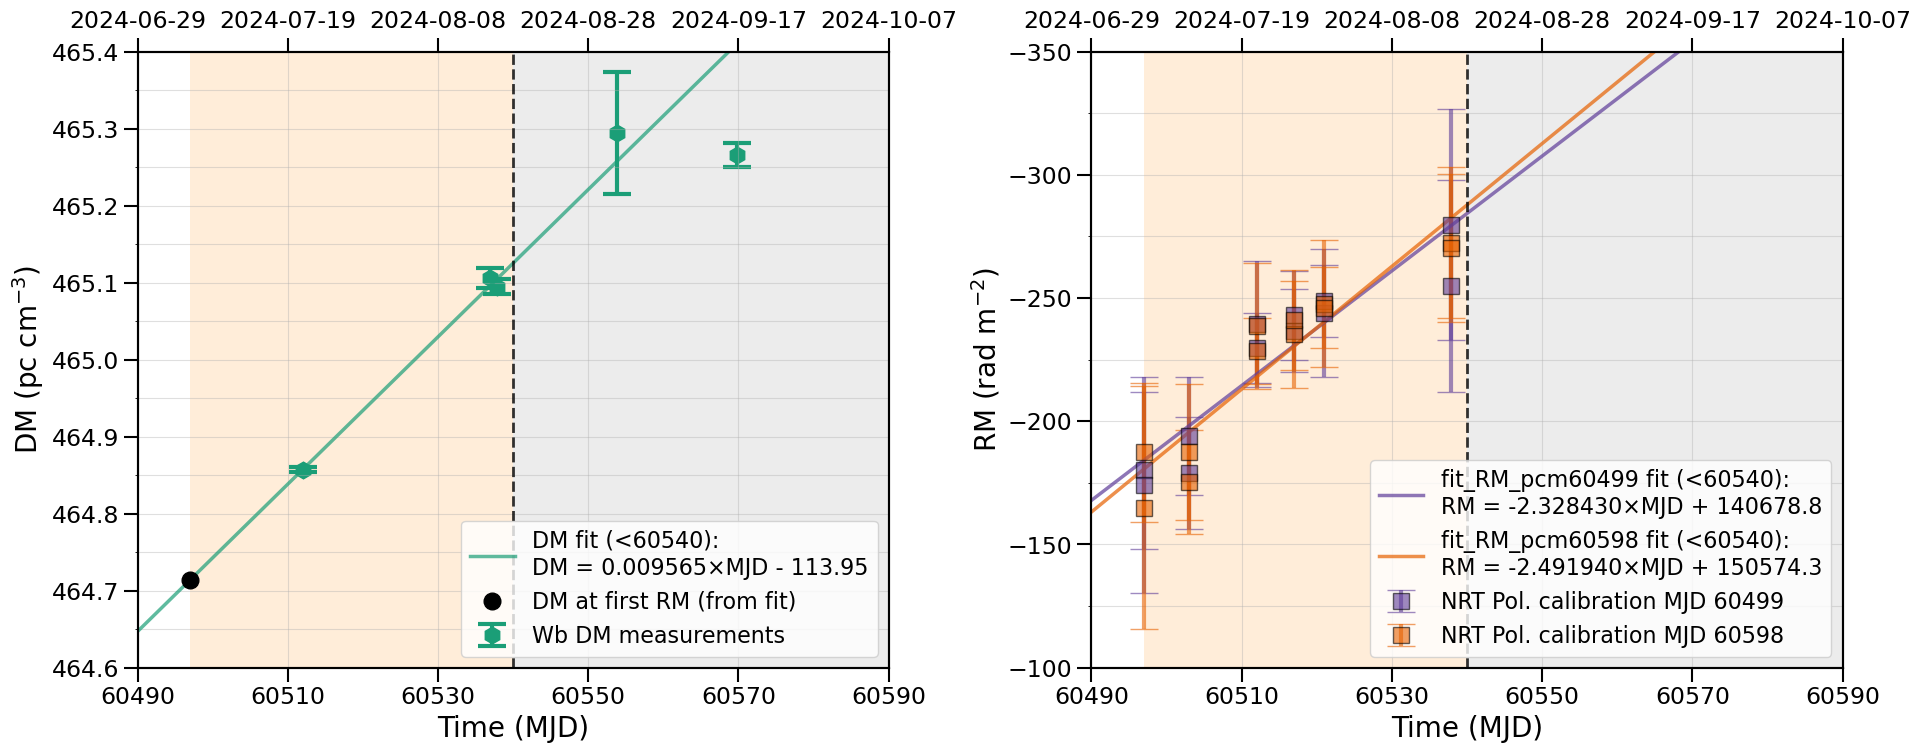

In [69]:
dm_df = pd.DataFrame({
    "MJD": [60511.987, 60536.878, 60537.882, 60553.893, 60569.758],
    "DM": [464.857, 465.106, 465.095, 465.294, 465.266],
    "DM_err": [0.003, 0.013, 0.010, 0.079, 0.016]
})
results = dm_rm_time_panel_with_fits(
    dm_df,
    cutoff=60540,
    dm_color="#1b9e77",
    rm_colors=["#5e3c99", "#e66101"],
    rm_csv_path="../../nrt_polarization/RM_values_and_errors.csv"
)